# Лабораторна робота №6
**Класифікація. Запобігання перенавчанню**  
**Виконав:** Брагнюк Андрій Романович  
**Група:** 4-8, ФІТ

**Мета:** дослідити ознаки датасету, навчити класифікатори, виконати балансування навчальних даних та підібрати гіперпараметри без витоку інформації з тестової вибірки.

Джерело: [Diabetes prediction dataset](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset). Цільова змінна — `diabetes`: 0 — відсутність діабету, 1 — наявність діабету за міткою датасету.

Комірки виконуються послідовно. Обрано один спосіб завантаження — архів Kaggle. Для першого запуску потрібен інтернет. Навчання SVC на повній збалансованій вибірці може тривати кілька хвилин.

In [1]:
import importlib.util
import subprocess
import sys
packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "sklearn": "scikit-learn",
            "imblearn": "imbalanced-learn", "xgboost": "xgboost",
            "lightgbm": "lightgbm", "catboost": "catboost"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Бібліотеки готові до роботи.")

Бібліотеки готові до роботи.


In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "2"
import io
import zipfile
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 10})
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__, "imbalanced-learn:", imblearn.__version__)

Python: 3.12.14
scikit-learn: 1.8.0 imbalanced-learn: 0.14.2


## 1. Завантаження і перевірка даних

In [3]:
csv_path = Path("diabetes_prediction_dataset.csv")
if not csv_path.exists():
    url = ("https://www.kaggle.com/api/v1/datasets/download/"
           "iammustafatz/diabetes-prediction-dataset")
    with urllib.request.urlopen(url, timeout=120) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    with archive:
        members = [name for name in archive.namelist() if Path(name).name == csv_path.name]
        if len(members) != 1:
            raise ValueError("В архіві не знайдено потрібний CSV.")
        csv_path.write_bytes(archive.read(members[0]))
df = pd.read_csv(csv_path)
print("Розмір датасету:", df.shape)
display(df.head())
df.info()
display(df.dtypes.to_frame("Тип даних"))

Розмір датасету: (100000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


,Тип даних
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


`gender` і `smoking_history` — категоріальні ознаки. `age`, `bmi`, `HbA1c_level` та `blood_glucose_level` — числові; `hypertension`, `heart_disease` і цільова змінна мають бінарні значення.

In [4]:
for column in ["gender", "smoking_history"]:
    print(column)
    display(df[column].value_counts(dropna=False).to_frame("Кількість"))
print("Баланс класів до видалення дублікатів:")
display(pd.DataFrame({"Кількість": df.diabetes.value_counts(),
                      "Частка, %": df.diabetes.value_counts(normalize=True) * 100}).round(2))
print("Пропущені значення:")
display(df.isna().sum().to_frame("Кількість"))
print("Повних дублікатів:", df.duplicated().sum())

gender
smoking_history
Баланс класів до видалення дублікатів:
Пропущені значення:
Повних дублікатів: 3854


,Кількість
gender,
Female,58552
Male,41430
Other,18


,Кількість
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


,Кількість,"Частка, %"
diabetes,,
0,91500,91.5
1,8500,8.5


,Кількість
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Клас 1 становить 8,5% початкових записів, тому класи незбалансовані. Значення `No Info` у `smoking_history` зберігається як окрема категорія: це відсутність інформації про куріння, а не підтвердження того, що людина не курить.

Після видалення дублікатів: (96146, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


,Кількість,"Частка, %"
diabetes,,
0,87664,91.18
1,8482,8.82


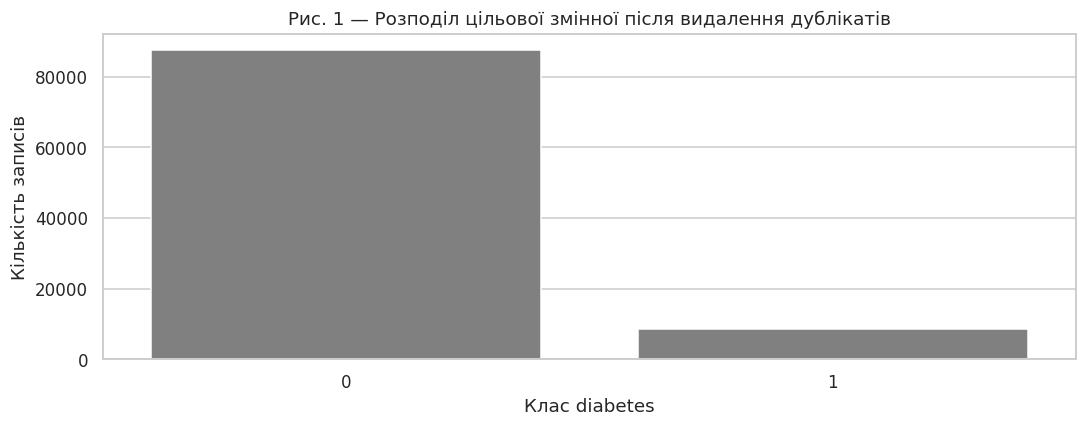

In [5]:
# Видаляю точні дублікати до поділу, щоб копії записів не опинилися в різних вибірках.
df = df.drop_duplicates().copy()
assert df.duplicated().sum() == 0
print("Після видалення дублікатів:", df.shape)
display(df.head())
display(pd.DataFrame({"Кількість": df.diabetes.value_counts().sort_index(),
                      "Частка, %": df.diabetes.value_counts(normalize=True).sort_index()*100}).round(2))
fig, ax = plt.subplots()
sns.countplot(data=df, x="diabetes", color="gray", ax=ax)
ax.set(title="Рис. 1 — Розподіл цільової змінної після видалення дублікатів",
       xlabel="Клас diabetes", ylabel="Кількість записів")
plt.tight_layout()
plt.show()

## 2. Поділ і кодування ознак

In [6]:
X = df.drop(columns="diabetes")
y = df["diabetes"]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

categorical_cols = ["gender", "smoking_history"]
X_train = pd.get_dummies(X_train_raw, columns=categorical_cols, dtype=float)
X_test = pd.get_dummies(X_test_raw, columns=categorical_cols, dtype=float)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

assert X_train.columns.equals(X_test.columns)
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
print("Train:", X_train.shape, "Test:", X_test.shape)
display(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}))
display(X_train.describe().T.round(3))
# Контроль незмінності відкладених даних.
X_test_reference, y_test_reference = X_test.copy(deep=True), y_test.copy(deep=True)

Train: (76916, 15) Test: (19230, 15)


,Train,Test
diabetes,,
0,70130,17534
1,6786,1696


,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.761,22.468,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078,0.268,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.041,0.198,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.314,6.757,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.531,1.072,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114,40.897,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.583,0.493,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417,0.493,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000,0.013,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342,0.474,0.00,0.00,0.00,1.00,1.00


## 3. Кореляції, викиди та асиметрія на train

Таблиця 1 — Кореляція ознак із diabetes на train
Пари ознак із |r| ≥ 0,7:


,Кореляція Пірсона
blood_glucose_level,0.423
HbA1c_level,0.405
age,0.267
bmi,0.213
hypertension,0.199
heart_disease,0.174
smoking_history_No Info,-0.113
smoking_history_former,0.096
gender_Male,0.041
gender_Female,-0.041


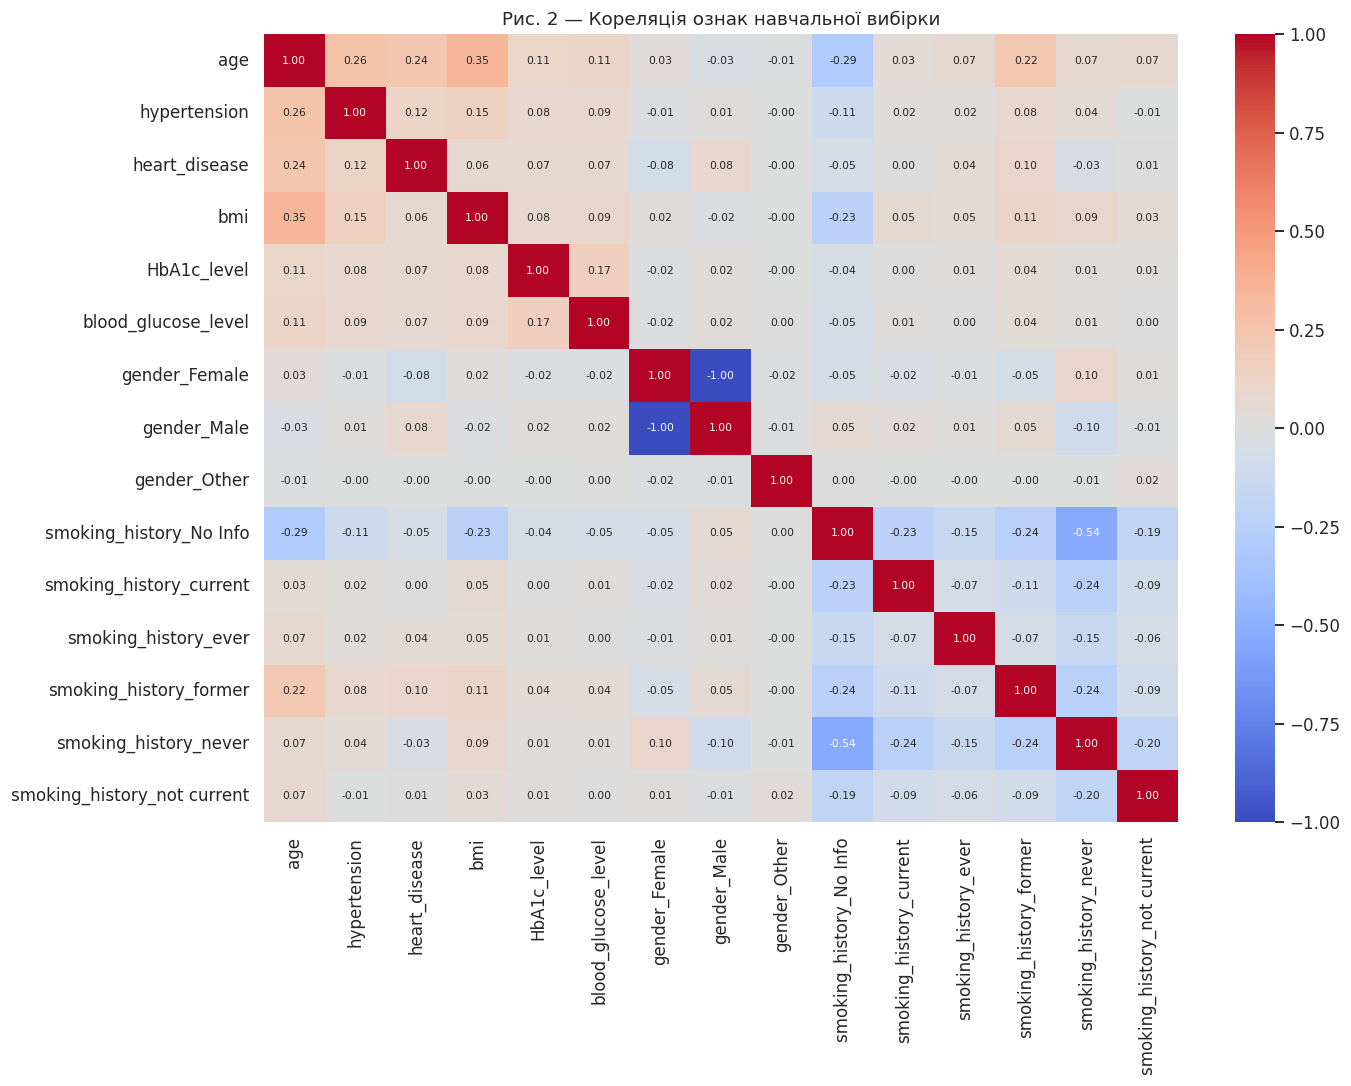

,,r
gender_Female,gender_Male,-1.0


In [7]:
target_corr = X_train.corrwith(y_train).sort_values(key=lambda s: s.abs(), ascending=False)
print("Таблиця 1 — Кореляція ознак із diabetes на train")
display(target_corr.to_frame("Кореляція Пірсона").round(3))
feature_corr = X_train.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(feature_corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Рис. 2 — Кореляція ознак навчальної вибірки")
plt.tight_layout()
plt.show()
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
strong_pairs = upper.stack().loc[lambda s: s.abs() >= 0.7]
print("Пари ознак із |r| ≥ 0,7:")
display(strong_pairs.to_frame("r").round(3))

Сильна від’ємна кореляція між індикаторами статі зумовлена взаємовиключністю категорій. One-hot-ознаки залишено: моделі використовують регуляризацію. Ознаки автоматично не видаляються лише за кореляцією; зв’язок із ціллю сам по собі не доводить причинності.

Пропуски після кодування:


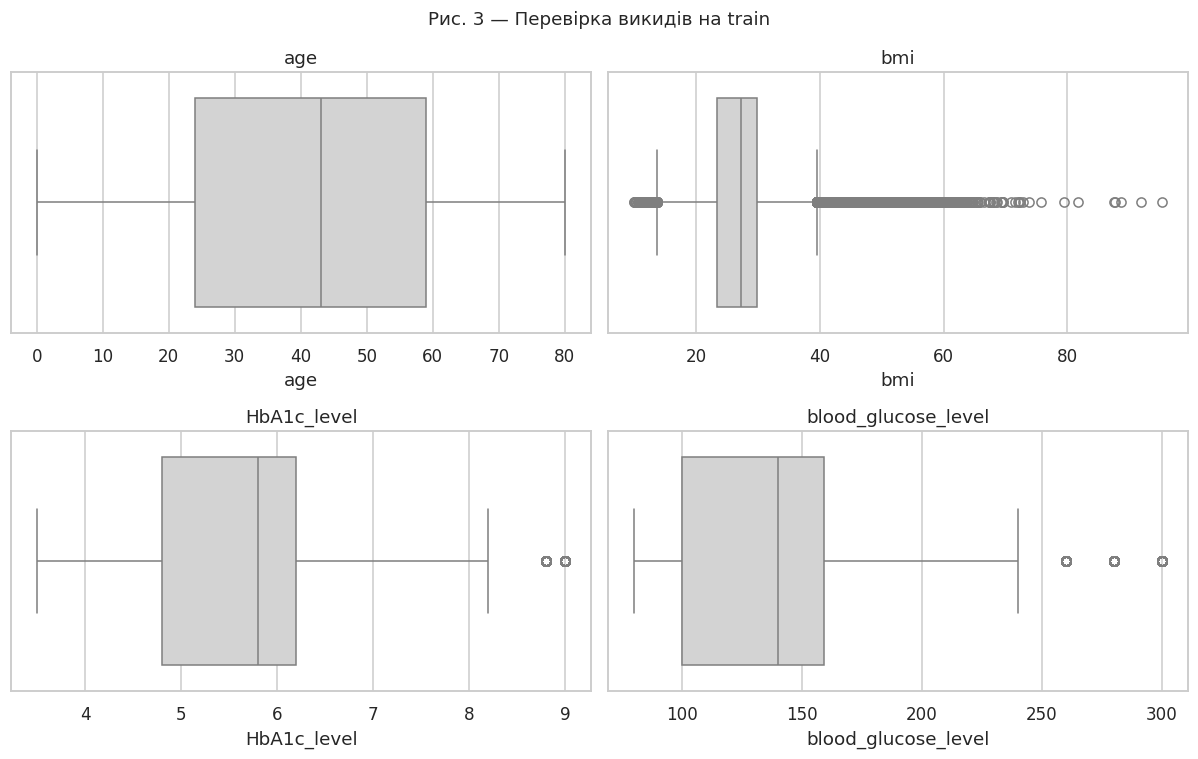

,Нижня межа,Верхня межа,За межами IQR,Асиметрія
Ознака,,,,
age,-28.5,111.50,0,-0.061
bmi,13.7,39.54,4244,1.005
HbA1c_level,2.7,8.30,1041,-0.056
blood_glucose_level,11.5,247.50,1598,0.831


,Train,Test
age,0,0
hypertension,0,0
heart_disease,0,0
bmi,0,0
HbA1c_level,0,0
blood_glucose_level,0,0
gender_Female,0,0
gender_Male,0,0
gender_Other,0,0
smoking_history_No Info,0,0


In [8]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
iqr_rows = []
for column, ax in zip(continuous_cols, axes.ravel()):
    sns.boxplot(x=X_train[column], color="lightgray", ax=ax)
    ax.set_title(column)
    q1, q3 = X_train[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper_bound = q1 - 1.5*iqr, q3 + 1.5*iqr
    outside = (X_train[column] < lower) | (X_train[column] > upper_bound)
    iqr_rows.append({"Ознака": column, "Нижня межа": lower,
                     "Верхня межа": upper_bound, "За межами IQR": int(outside.sum()),
                     "Асиметрія": X_train[column].skew()})
fig.suptitle("Рис. 3 — Перевірка викидів на train")
plt.tight_layout()
plt.show()
iqr_table = pd.DataFrame(iqr_rows).set_index("Ознака")
display(iqr_table.round(3))
print("Пропуски після кодування:")
display(pd.DataFrame({"Train": X_train.isna().sum(), "Test": X_test.isna().sum()}))

Межі IQR та асиметрію обчислено тільки на train. Для `bmi` межі визначаються як Q1 − 1,5·IQR і Q3 + 1,5·IQR; відповідні рядки лише підраховано. Викиди не видаляються: екстремальні значення можуть бути змістовними для класифікації. Дисбаланс усувається тільки в навчальній вибірці; test зберігає початковий розподіл класів.

## 4. Масштабування та SMOTE

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
smote = SMOTE(random_state=SEED)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)
display(pd.DataFrame({"До SMOTE": y_train.value_counts().sort_index(),
                      "Після SMOTE": pd.Series(y_train_balanced).value_counts().sort_index()}))
print("Форма збалансованої навчальної вибірки:", X_train_balanced.shape)

Форма збалансованої навчальної вибірки: (140260, 15)


,До SMOTE,Після SMOTE
diabetes,,
0,70130,70130
1,6786,70130


Відповідно до шаблону застосовано звичайний SMOTE після one-hot-кодування. Його синтетичні значення бінарних індикаторів можуть бути дробовими. Це обмеження використаної схеми; синтетичні записи не додаються до test.

## 5. Базові моделі

Навчання: LogisticRegression
LogisticRegression
              precision    recall  f1-score   support

           0     0.9870    0.8854    0.9334     17534
           1     0.4260    0.8791    0.5739      1696

    accuracy                         0.8849     19230
   macro avg     0.7065    0.8823    0.7537     19230
weighted avg     0.9375    0.8849    0.9017     19230

Навчання: RidgeClassifier
RidgeClassifier
              precision    recall  f1-score   support

           0     0.9866    0.8889    0.9352     17534
           1     0.4324    0.8750    0.5788      1696

    accuracy                         0.8877     19230
   macro avg     0.7095    0.8820    0.7570     19230
weighted avg     0.9377    0.8877    0.9038     19230

Навчання: SGDClassifier
SGDClassifier
              precision    recall  f1-score   support

           0     0.9898    0.8563    0.9182     17534
           1     0.3796    0.9086    0.5354      1696

    accuracy                         0.8609     19230


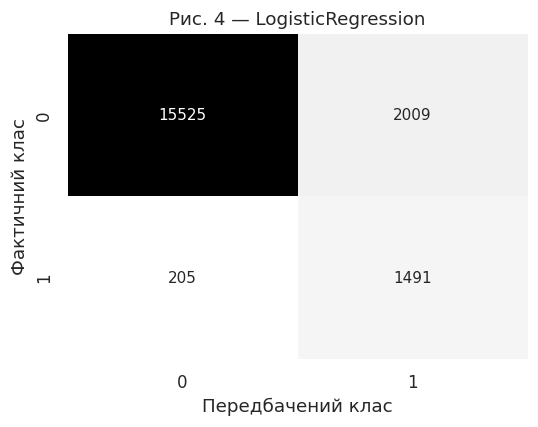

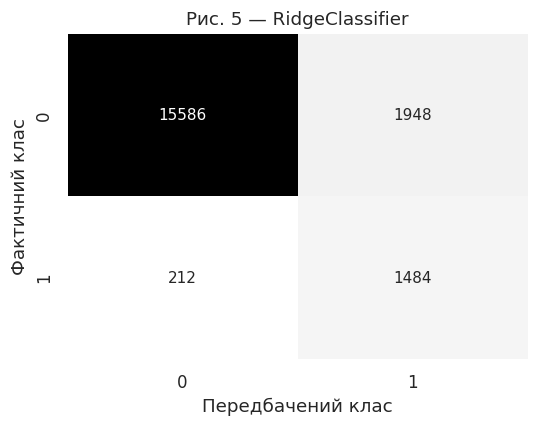

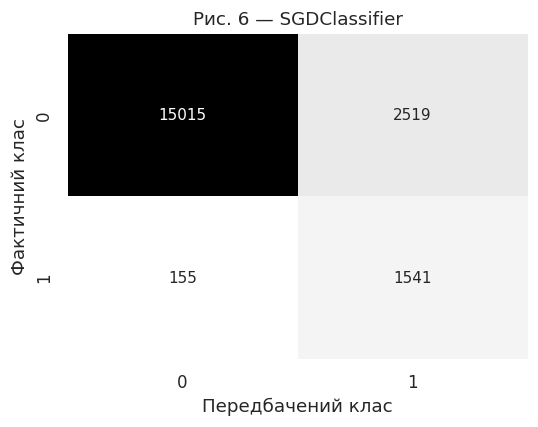

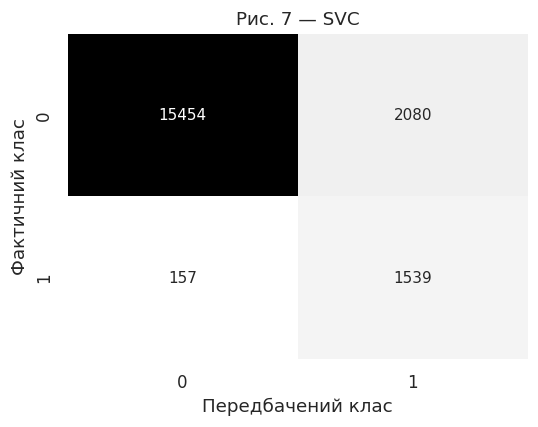

,Accuracy,Precision (1),Recall (1),F1 (1),F1 train (1)
LogisticRegression,0.8849,0.4260,0.8791,0.5739,0.5799
RidgeClassifier,0.8877,0.4324,0.8750,0.5788,0.5858
SGDClassifier,0.8609,0.3796,0.9086,0.5354,0.5464
SVC,0.8837,0.4253,0.9074,0.5791,0.5957


In [10]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=3000, random_state=SEED),
    "RidgeClassifier": RidgeClassifier(random_state=SEED),
    "SGDClassifier": SGDClassifier(max_iter=3000, tol=1e-3, random_state=SEED),
    "SVC": SVC(kernel="rbf", cache_size=1000, random_state=SEED)
}


def quality(actual, prediction):
    return {"Accuracy": accuracy_score(actual, prediction),
            "Precision (1)": precision_score(actual, prediction, zero_division=0),
            "Recall (1)": recall_score(actual, prediction, zero_division=0),
            "F1 (1)": f1_score(actual, prediction, zero_division=0)}


def report_model(name, prediction, figure_number):
    print(name)
    print(classification_report(y_test, prediction, digits=4, zero_division=0))
    matrix = confusion_matrix(y_test, prediction, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Greys", cbar=False,
                xticklabels=[0, 1], yticklabels=[0, 1], ax=ax)
    ax.set(title=f"Рис. {figure_number} — {name}",
           xlabel="Передбачений клас", ylabel="Фактичний клас")
    plt.tight_layout()
    plt.show()


base_metrics, base_predictions = {}, {}
for number, (name, model) in enumerate(models.items(), start=4):
    print("Навчання:", name, flush=True)
    model.fit(X_train_balanced, y_train_balanced)
    prediction = model.predict(X_test_scaled)
    base_predictions[name] = prediction
    base_metrics[name] = quality(y_test, prediction)
    base_metrics[name]["F1 train (1)"] = f1_score(y_train, model.predict(X_train_scaled))
    report_model(name, prediction, number)
base_results = pd.DataFrame(base_metrics).T
print("Таблиця 2 — Базові моделі")
display(base_results.round(4))

## 6. Підбір гіперпараметрів

In [11]:
# Для кожної моделі — 9 комбінацій, однакові ресурси пошуку та cv=3.
param_grids = {
    "LogisticRegression": {"model__C": [0.1, 1.0, 10.0],
                           "model__solver": ["liblinear", "lbfgs", "newton-cg"]},
    "RidgeClassifier": {"model__alpha": [0.001, 0.01, 0.1, 1, 10, 30, 100, 300, 1000]},
    "SGDClassifier": {"model__alpha": [0.0001, 0.001, 0.01],
                      "model__loss": ["hinge", "log_loss", "modified_huber"]},
    "SVC": {"model__C": [0.1, 1.0, 10.0], "model__kernel": ["linear", "rbf", "poly"]}
}

`HalvingGridSearchCV` використовує `cv=3`, `scoring="f1"` і `min_resources=300`. На кожному етапі залишаються найкращі кандидати, а кількість навчальних записів збільшується. `StandardScaler` і `SMOTE` включено в `Pipeline`: валідаційні згини не беруть участі в їх навчанні.

Кількість кандидатів і схема розподілу ресурсів однакові для всіх чотирьох моделей. Значення CV F1 стосується останнього етапу пошуку на підвибірках train; після пошуку найкращий pipeline повторно навчається на всьому train (`refit=True`).

In [12]:
best_models, best_scores, searches = {}, {}, {}
search_rows = []
for name, model in models.items():
    print("Підбір параметрів:", name, flush=True)
    pipeline = Pipeline([("scaler", StandardScaler()),
                         ("smote", SMOTE(random_state=SEED)),
                         ("model", clone(model))])
    search = HalvingGridSearchCV(
        pipeline, param_grids[name], cv=3, scoring="f1",
        min_resources=300, factor=3, resource="n_samples",
        random_state=SEED, n_jobs=1, refit=True,
        return_train_score=True, error_score="raise")
    search.fit(X_train, y_train)
    searches[name] = search
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    row = search.best_index_
    search_rows.append({"Модель": name, "CV F1": search.best_score_,
                       "CV F1 std": search.cv_results_["std_test_score"][row],
                       "F1 навчальних згинів": search.cv_results_["mean_train_score"][row],
                       "Ресурс останнього етапу": search.n_resources_[-1]})
    print("Параметри:", search.best_params_)
    print("Ресурси:", search.n_resources_, "Кандидати:", search.n_candidates_)
    print("Середній CV F1:", round(search.best_score_, 4))
cv_results = pd.DataFrame(search_rows).set_index("Модель").sort_values("CV F1", ascending=False)
print("Таблиця 3 — Результати кросвалідації")
display(cv_results.round(4))

# Назву переможця фіксую до перегляду тестових метрик оптимізованих моделей.
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print("Обрана модель:", best_name)
print("CV F1:", round(best_scores[best_name], 4))

Підбір параметрів: LogisticRegression
Параметри: {'model__C': 1.0, 'model__solver': 'lbfgs'}
Ресурси: [300, 900, 2700] Кандидати: [9, 3, 1]
Середній CV F1: 0.6324
Підбір параметрів: RidgeClassifier
Параметри: {'model__alpha': 300}
Ресурси: [300, 900, 2700] Кандидати: [9, 3, 1]
Середній CV F1: 0.6358
Підбір параметрів: SGDClassifier
Параметри: {'model__alpha': 0.0001, 'model__loss': 'log_loss'}
Ресурси: [300, 900, 2700] Кандидати: [9, 3, 1]
Середній CV F1: 0.5936
Підбір параметрів: SVC
Параметри: {'model__C': 0.1, 'model__kernel': 'poly'}
Ресурси: [300, 900, 2700] Кандидати: [9, 3, 1]
Середній CV F1: 0.67
Таблиця 3 — Результати кросвалідації
Обрана модель: SVC
CV F1: 0.67


,CV F1,CV F1 std,F1 навчальних згинів,Ресурс останнього етапу
Модель,,,,
SVC,0.6700,0.0463,0.7320,2700
RidgeClassifier,0.6358,0.0489,0.6192,2700
LogisticRegression,0.6324,0.0542,0.6223,2700
SGDClassifier,0.5936,0.0412,0.5833,2700


## 7. Перевірка оптимізованих моделей на test

LogisticRegression після підбору
              precision    recall  f1-score   support

           0     0.9870    0.8854    0.9334     17534
           1     0.4260    0.8791    0.5739      1696

    accuracy                         0.8849     19230
   macro avg     0.7065    0.8823    0.7537     19230
weighted avg     0.9375    0.8849    0.9017     19230

RidgeClassifier після підбору
              precision    recall  f1-score   support

           0     0.9866    0.8888    0.9352     17534
           1     0.4323    0.8750    0.5787      1696

    accuracy                         0.8876     19230
   macro avg     0.7094    0.8819    0.7569     19230
weighted avg     0.9377    0.8876    0.9037     19230

SGDClassifier після підбору
              precision    recall  f1-score   support

           0     0.9868    0.8839    0.9325     17534
           1     0.4224    0.8774    0.5702      1696

    accuracy                         0.8834     19230
   macro avg     0.7046    0.8806    

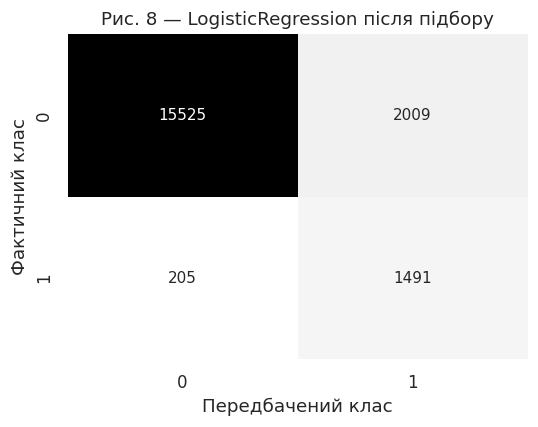

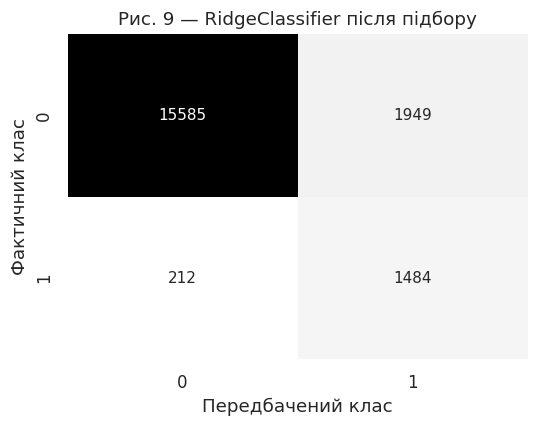

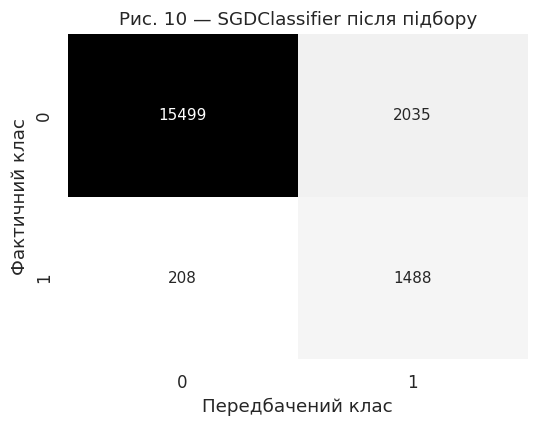

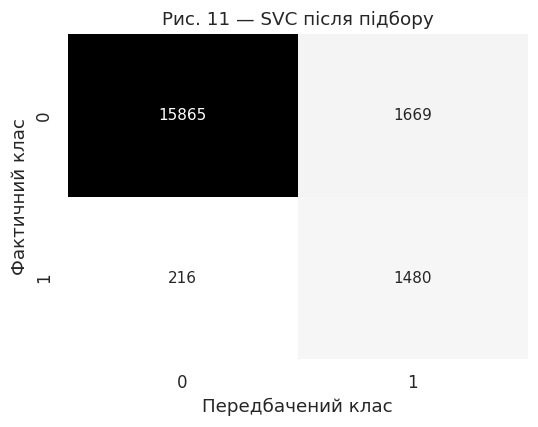

,Accuracy,Precision (1),Recall (1),F1 (1),F1 train (1)
LogisticRegression,0.8849,0.4260,0.8791,0.5739,0.5799
RidgeClassifier,0.8876,0.4323,0.8750,0.5787,0.5860
SGDClassifier,0.8834,0.4224,0.8774,0.5702,0.5777
SVC,0.9020,0.4700,0.8726,0.6109,0.6249


,F1 до підбору,F1 після підбору,Recall до підбору,Recall після підбору
LogisticRegression,0.5739,0.5739,0.8791,0.8791
RidgeClassifier,0.5788,0.5787,0.8750,0.8750
SGDClassifier,0.5354,0.5702,0.9086,0.8774
SVC,0.5791,0.6109,0.9074,0.8726


In [13]:
tuned_metrics, tuned_predictions = {}, {}
for number, (name, model) in enumerate(best_models.items(), start=8):
    prediction = model.predict(X_test)
    tuned_predictions[name] = prediction
    tuned_metrics[name] = quality(y_test, prediction)
    tuned_metrics[name]["F1 train (1)"] = f1_score(y_train, model.predict(X_train))
    report_model(name + " після підбору", prediction, number)
tuned_results = pd.DataFrame(tuned_metrics).T
print("Таблиця 4 — Оптимізовані моделі на test")
display(tuned_results.round(4))
comparison = pd.DataFrame({"F1 до підбору": base_results["F1 (1)"],
                          "F1 після підбору": tuned_results["F1 (1)"],
                          "Recall до підбору": base_results["Recall (1)"],
                          "Recall після підбору": tuned_results["Recall (1)"]})
print("Таблиця 5 — Порівняння до та після підбору")
display(comparison.round(4))

Найкраща модель визначена за CV F1, а тестові результати наведені для остаточної перевірки. Розрив між F1 навчальних і валідаційних згинів використовується як індикатор можливого перенавчання. Один поділ даних не доводить відсутності перенавчання.

Для обраної моделі SVC середній F1 навчальних згинів становить 0.7320, валідаційних — 0.6700; різниця — 0.0620. Ці оцінки отримано на останньому етапі пошуку з ресурсом 2700 записів. Тестовий F1 після навчання на всьому train наведено окремо в таблиці 4.

In [14]:
sample_indices = X_test.sample(n=10, random_state=SEED).index
sample_predictions = best_model.predict(X_test.loc[sample_indices])
examples = pd.DataFrame({"Індекс": sample_indices,
                         "Істинний клас": y_test.loc[sample_indices].to_numpy(),
                         "Передбачений клас": sample_predictions})
print("Таблиця 6 — Десять випадкових тестових прогнозів:", best_name)
display(examples)

Таблиця 6 — Десять випадкових тестових прогнозів: SVC


,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,0
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,0
9,37072,0,0


## 8. Додаткове завдання: XGBoost, LightGBM, CatBoost

Додаткові моделі навчаються на тій самій збалансованій навчальній вибірці й оцінюються на незміненому test. Їх параметри задано до отримання тестових результатів. Ці моделі не беруть участі у виборі переможця серед чотирьох основних моделей за CV.

Навчання: XGBoost
XGBoost
              precision    recall  f1-score   support

           0     0.9786    0.9747    0.9767     17534
           1     0.7490    0.7795    0.7639      1696

    accuracy                         0.9575     19230
   macro avg     0.8638    0.8771    0.8703     19230
weighted avg     0.9583    0.9575    0.9579     19230

Навчання: LightGBM
LightGBM
              precision    recall  f1-score   support

           0     0.9722    0.9958    0.9839     17534
           1     0.9425    0.7052    0.8067      1696

    accuracy                         0.9702     19230
   macro avg     0.9573    0.8505    0.8953     19230
weighted avg     0.9695    0.9702    0.9682     19230

Навчання: CatBoost
CatBoost
              precision    recall  f1-score   support

           0     0.9726    0.9961    0.9842     17534
           1     0.9465    0.7099    0.8113      1696

    accuracy                         0.9709     19230
   macro avg     0.9596    0.8530    0.8978   

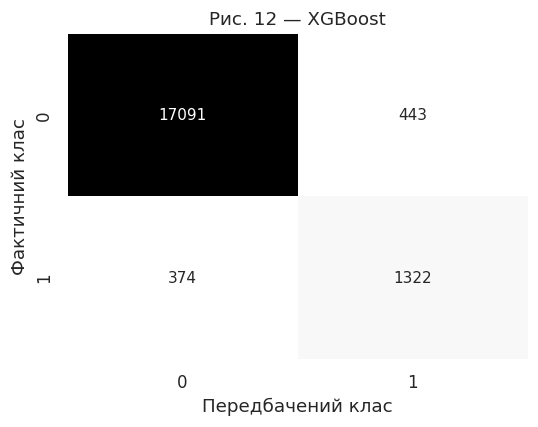

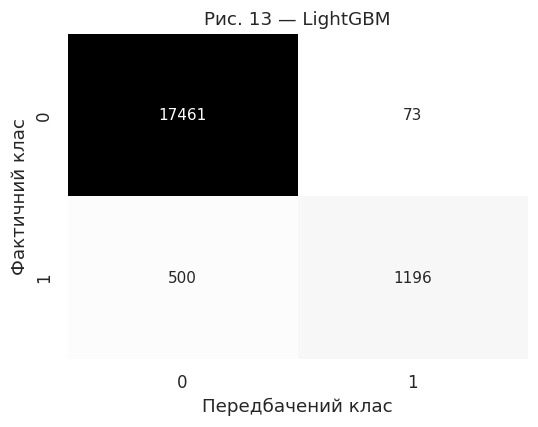

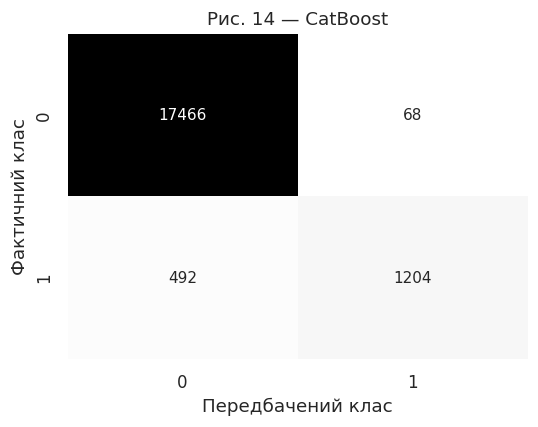

,Accuracy,Precision (1),Recall (1),F1 (1)
XGBoost,0.9575,0.7490,0.7795,0.7639
LightGBM,0.9702,0.9425,0.7052,0.8067
CatBoost,0.9709,0.9465,0.7099,0.8113


In [15]:
extra_models = {
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        eval_metric="logloss", tree_method="hist", n_jobs=2, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=200, num_leaves=15, learning_rate=0.05,
        reg_lambda=1.0, verbosity=-1, n_jobs=2, random_state=SEED),
    "CatBoost": CatBoostClassifier(iterations=300, depth=5, learning_rate=0.05,
        l2_leaf_reg=3, loss_function="Logloss", random_seed=SEED,
        thread_count=2, verbose=False, allow_writing_files=False)
}
# Однакові назви колонок під час fit/predict для всіх додаткових моделей.
X_balanced_frame = pd.DataFrame(X_train_balanced, columns=X_train.columns)
X_test_frame = pd.DataFrame(X_test_scaled, columns=X_train.columns, index=X_test.index)
extra_metrics = {}
for number, (name, model) in enumerate(extra_models.items(), start=12):
    print("Навчання:", name, flush=True)
    model.fit(X_balanced_frame, y_train_balanced)
    prediction = model.predict(X_test_frame).ravel().astype(int)
    extra_metrics[name] = quality(y_test, prediction)
    report_model(name, prediction, number)
extra_results = pd.DataFrame(extra_metrics).T
print("Таблиця 7 — Додаткові моделі")
display(extra_results.round(4))

Перевірка: склад і значення тестової вибірки не змінено.


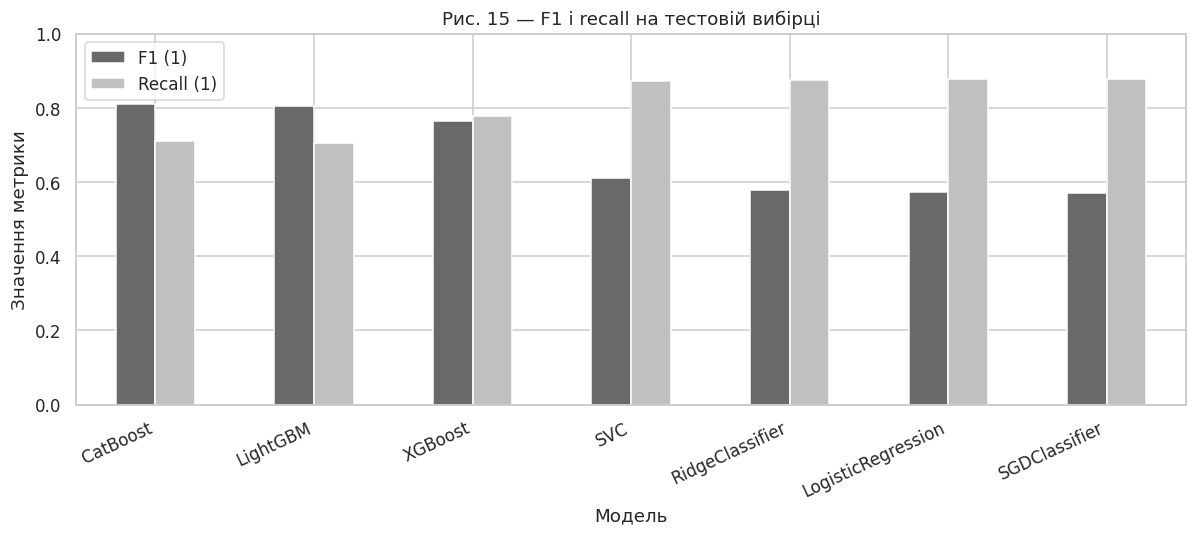

In [16]:
all_results = pd.concat([
    tuned_results[["Accuracy", "Precision (1)", "Recall (1)", "F1 (1)"]],
    extra_results
]).sort_values("F1 (1)", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
all_results[["F1 (1)", "Recall (1)"]].plot.bar(ax=ax, color=["dimgray", "silver"])
ax.set(title="Рис. 15 — F1 і recall на тестовій вибірці", ylabel="Значення метрики", xlabel="Модель", ylim=(0, 1))
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
assert X_test.equals(X_test_reference) and y_test.equals(y_test_reference)
print("Перевірка: склад і значення тестової вибірки не змінено.")

## 9. Короткі висновки

In [17]:
positive_fraction = y_train.mean() * 100
strongest = ", ".join(target_corr.index[:3])
best_f1_test = tuned_results["F1 (1)"].idxmax()
best_recall_test = tuned_results["Recall (1)"].idxmax()
tn, fp, fn, tp = confusion_matrix(y_test, tuned_predictions[best_name], labels=[0, 1]).ravel()
print(f"1. Частка класу 1 у train — {positive_fraction:.2f}%. SMOTE вирівняв лише навчальні класи.")
print(f"   Найбільша абсолютна кореляція з ціллю: {strongest}.")
print("   Межі IQR визначено на train; екстремальні значення збережено.")
print(f"2. Серед основних моделей після підбору найбільший тестовий F1 має {best_f1_test} "
      f"({tuned_results.loc[best_f1_test, 'F1 (1)']:.4f}), recall — {best_recall_test} "
      f"({tuned_results.loc[best_recall_test, 'Recall (1)']:.4f}).")
print(f"   За кросвалідацією обрано {best_name}; CV F1 = {best_scores[best_name]:.4f}.")
print("3. Параметри обраної моделі:", searches[best_name].best_params_)
print(f"   На test: TN={tn}, FP={fp}, FN={fn}, TP={tp}. FP — хибні позитивні, FN — пропущені позитивні випадки.")
print("4. Test використано тільки для оцінювання. Pipeline навчає scaler і SMOTE всередині навчальних згинів, "
      "що запобігає витоку даних під час підбору параметрів.")
extra_f1 = extra_results["F1 (1)"].idxmax()
print(f"5. Серед додаткових моделей найбільший тестовий F1 має {extra_f1}: "
      f"{extra_results.loc[extra_f1, 'F1 (1)']:.4f}; recall — {extra_results.loc[extra_f1, 'Recall (1)']:.4f}.")

1. Частка класу 1 у train — 8.82%. SMOTE вирівняв лише навчальні класи.
   Найбільша абсолютна кореляція з ціллю: blood_glucose_level, HbA1c_level, age.
   Межі IQR визначено на train; екстремальні значення збережено.
2. Серед основних моделей після підбору найбільший тестовий F1 має SVC (0.6109), recall — LogisticRegression (0.8791).
   За кросвалідацією обрано SVC; CV F1 = 0.6700.
3. Параметри обраної моделі: {'model__C': 0.1, 'model__kernel': 'poly'}
   На test: TN=15865, FP=1669, FN=216, TP=1480. FP — хибні позитивні, FN — пропущені позитивні випадки.
4. Test використано тільки для оцінювання. Pipeline навчає scaler і SMOTE всередині навчальних згинів, що запобігає витоку даних під час підбору параметрів.
5. Серед додаткових моделей найбільший тестовий F1 має CatBoost: 0.8113; recall — 0.7099.
